In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from affine import Affine

import config 
import schema
import landcover_join as lj



In [2]:
firms = pd.read_parquet(config.PROCESSED_DIR / "firms_clean.parquet")
fire_weather = pd.read_parquet(config.PROCESSED_DIR / "fire_weather.parquet")
weather = pd.read_parquet(config.PROCESSED_DIR / "weather_daily.parquet")

maps = lj.load_all_landcover()

southeast_asia 3,901 x 5,127 pixels, each about 478 x 499 m


In [3]:
latitude = 18.0
native = Affine(3 / 36000, 0, 0, 0, -3 / 36000, 0)   # a WorldCover tile is 3 degrees = 36,000 pixels
native_w, native_h = lj.pixel_size_m(native, latitude)

viirs_inside = (375 / native_w) * (375 / native_h)
era5_inside = (0.1 / (3 / 36000)) ** 2

pd.DataFrame([
    {"source": "ESA WorldCover pixel", "size": f"{native_w:.1f} x {native_h:.1f} m", "WorldCover pixels inside": 1},
    {"source": "VIIRS hotspot pixel", "size": "about 375 m", "WorldCover pixels inside": round(viirs_inside)},
    {"source": "ERA5-Land grid cell", "size": "0.1 degrees (about 11 km)", "WorldCover pixels inside": round(era5_inside)},
]).set_index("source")

,size,WorldCover pixels inside
source,,
ESA WorldCover pixel,8.8 x 9.3 m,1
VIIRS hotspot pixel,about 375 m,1718
ERA5-Land grid cell,0.1 degrees (about 11 km),1440000


In [4]:
pd.DataFrame([
    {"code": code, "class": config.LAND_COVER_CLASSES[code][0], "group": lj.group_name(code)}
    for code in sorted(config.LAND_COVER_CLASSES)
]).set_index("code")

,class,group
code,,
10,Tree cover,forest
20,Shrubland,grassland
30,Grassland,grassland
40,Cropland,cropland
50,Built-up,other
60,Bare / sparse vegetation,other
70,Snow and ice,other
80,Permanent water bodies,other
90,Herbaceous wetland,other


In [5]:
point_parts = []
both_parts = []

for name, (data, transform) in maps.items():
    west, south, east, north = [float(x) for x in config.STUDY_REGIONS[name].split(",")]
    in_region = firms["longitude"].between(west, east) & firms["latitude"].between(south, north)
    subset = firms[in_region]

    at_points = lj.landcover_at_points(subset, data, transform)
    at_points["region"] = name
    point_parts.append(at_points)

    # The neighbourhood lookup is slower, so it is run on a random sample
    sample = subset.sample(n=min(20000, len(subset)), random_state=0)
    sample = lj.landcover_at_points(sample, data, transform)
    both_parts.append(lj.landcover_around_points(sample, data, transform))

points = pd.concat(point_parts, ignore_index=True)
print(f"{len(points):,} hotspots lie inside a land cover map")
points["landcover_status"].value_counts()

5,030,113 hotspots lie inside a land cover map


landcover_status
ok    5030113
Name: count, dtype: int64

In [6]:
ok = points[points["landcover_status"] == "ok"]
share = ok["landcover_group"].value_counts(normalize=True).mul(100).round(1)
share.rename("% of hotspots").to_frame()

,% of hotspots
landcover_group,
forest,70.5
cropland,17.1
grassland,11.6
other,0.8


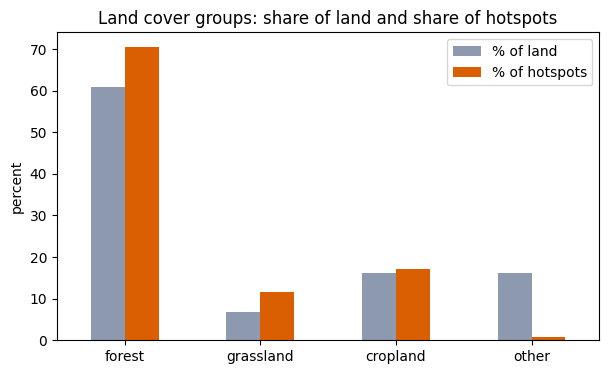

In [7]:
area_counts = np.zeros(len(lj.GROUP_NAMES))
for name, (data, transform) in maps.items():
    group_numbers = lj.GROUP_LOOKUP[data.ravel()]
    group_numbers = group_numbers[group_numbers >= 0]
    area_counts = area_counts + np.bincount(group_numbers, minlength=len(lj.GROUP_NAMES))
area_share = pd.Series(area_counts / area_counts.sum() * 100, index=lj.GROUP_NAMES)

compare = pd.DataFrame({
    "% of land": area_share.round(1),
    "% of hotspots": share.reindex(lj.GROUP_NAMES).fillna(0),
})

ax = compare.plot.bar(figsize=(7, 4), color=["#8d99ae", "#d95f02"])
ax.set_ylabel("percent")
ax.set_title("Land cover groups: share of land and share of hotspots")
plt.xticks(rotation=0)
plt.show()

In [8]:
both = pd.concat(both_parts, ignore_index=True)
both = both[both["landcover_status"] == "ok"].dropna(subset=["around_group"])

agree = (both["landcover_group"] == both["around_group"])
print(f"Hotspots compared                    : {len(both):,}")
print(f"Pixel under the hotspot = main group of its 375 m square: {agree.mean() * 100:.1f}%")
print(f"Median share of the square held by its main group       : {both['around_group_pct'].median():.0f}%")

Hotspots compared                    : 20,000
Pixel under the hotspot = main group of its 375 m square: 92.1%
Median share of the square held by its main group       : 100%


In [9]:
pd.crosstab(both["landcover_group"], both["around_group"],rownames=["pixel under hotspot"], colnames=["main group around it"])

main group around it,cropland,forest,grassland,other
pixel under hotspot,,,,
cropland,3031,250,102,5
forest,171,13638,224,7
grassland,112,647,1651,0
other,15,42,1,104


In [10]:
cells = lj.landcover_for_cells(weather["grid_id"].unique(), maps)
cells.head()

25,702 of 25,704 cells have land cover (coverage of at least 50%)
  363 cell(s) are only partly covered (at the edge of a map)


,grid_id,landcover_coverage_pct,forest_pct,grassland_pct,cropland_pct,other_pct,land_cover_dominant,region
0,10.0_105.1,100.0,3.82,3.99,48.61,43.58,cropland,southeast_asia
1,10.0_105.2,100.0,0.91,0.00,98.37,0.72,cropland,southeast_asia
2,10.0_105.3,100.0,0.00,0.00,100.00,0.00,cropland,southeast_asia
3,10.0_105.4,100.0,9.38,0.00,90.45,0.17,cropland,southeast_asia
4,10.0_105.5,100.0,3.99,0.00,94.75,1.27,cropland,southeast_asia


In [11]:
cells["land_cover_dominant"].value_counts(dropna=False).rename("cells").to_frame()

,cells
land_cover_dominant,
forest,19726
cropland,4474
grassland,934
other,568
NaN,2


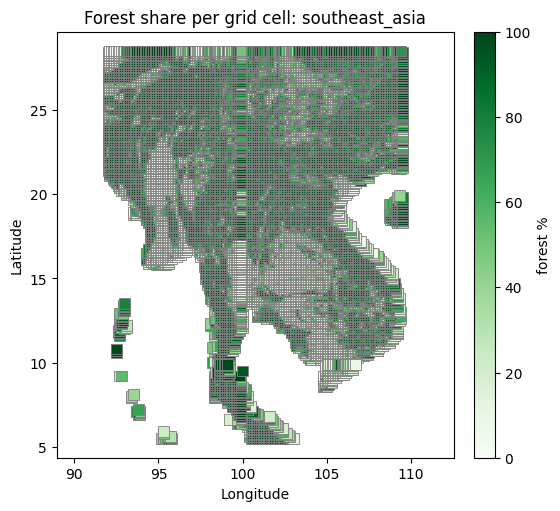

In [12]:
fig, axes = plt.subplots(1, len(maps), figsize=(5.5 * len(maps), 5), constrained_layout=True)
if len(maps) == 1:
    axes = [axes]

for ax, name in zip(axes, maps):
    region_cells = cells[cells["region"] == name].dropna(subset=["forest_pct"])
    lats = [schema.grid_id_to_latlon(g)[0] for g in region_cells["grid_id"]]
    lons = [schema.grid_id_to_latlon(g)[1] for g in region_cells["grid_id"]]
    points_plot = ax.scatter(lons, lats, c=region_cells["forest_pct"], cmap="Greens", vmin=0, vmax=100, s=60, marker="s", edgecolors="grey", linewidths=0.6)
    ax.set_title(f"Forest share per grid cell: {name}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal", adjustable="datalim")
    fig.colorbar(points_plot, ax=ax, label="forest %")
plt.show()

In [13]:
lj.save_landcover_cells(cells)

Saved 25,704 cells -> D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\landcover_cells.parquet


WindowsPath('D:/Duanduhoche.Huy/wildfire-risk-analysis/data/processed/landcover_cells.parquet')

In [14]:
final = lj.add_landcover(fire_weather, cells)
final.head()

1,665,011 of 1,665,011 rows got land cover (0 did not)


,grid_id,date,hotspot_count,frp_max,frp_sum,fire,latitude,longitude,country,year,...,rainfall_mm,wind_speed_kmh,rainfall_7d_mm,dry_days,land_cover_dominant,forest_pct,grassland_pct,cropland_pct,other_pct,landcover_coverage_pct
0,10.0_105.1,2020-03-08,3,3.07,8.67,1,10.0,105.1,VNM,2020,...,0.535705,10.899910,1.484022,19,cropland,3.82,3.99,48.61,43.58,100.0
1,10.0_105.1,2020-03-11,1,4.54,4.54,1,10.0,105.1,VNM,2020,...,1.079464,7.059115,2.964859,0,cropland,3.82,3.99,48.61,43.58,100.0
2,10.0_105.1,2020-03-13,1,10.63,10.63,1,10.0,105.1,VNM,2020,...,0.040591,9.954636,3.925697,1,cropland,3.82,3.99,48.61,43.58,100.0
3,10.0_105.1,2020-03-14,1,1.90,1.90,1,10.0,105.1,VNM,2020,...,0.041455,13.373718,3.778289,2,cropland,3.82,3.99,48.61,43.58,100.0
4,10.0_105.1,2020-03-17,2,13.56,17.65,1,10.0,105.1,VNM,2020,...,0.178570,13.794793,2.598798,5,cropland,3.82,3.99,48.61,43.58,100.0


In [15]:
schema.check_primary_key(final)
problems = schema.validate_schema(final)

check_primary_key: OK - all 1665011 rows have a unique (grid_id, date)
validate_schema: OK - 1665011 rows, 24 columns


In [16]:
final.to_parquet(config.PROCESSED_DIR / "fire_weather_landcover.parquet", index=False)
print(f"Saved {len(final):,} rows")

Saved 1,665,011 rows
